# Retail Sales Analysis and Sales Prediction Using Linear Regression
**Intern:** Itika Kansal  
**Dataset:** Superstore Sales Dataset (Kaggle – vivek468)  
**Technologies:** Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn  

---
## Project Objective
This notebook walks through a complete data-analytics pipeline on a real retail dataset:
1. Clean and prepare raw data
2. Explore sales and profit patterns
3. Visualise key business trends
4. Build a Linear Regression model to predict monthly sales
5. Extract actionable business insights

> **Beginner tip:** Every section starts with a plain-English explanation of *what* we are doing and *why*.

---
## Section 0 – Import Libraries
We begin by importing every library we need.  
- **pandas** – tabular data (DataFrames)  
- **numpy** – fast numerical operations  
- **matplotlib / seaborn** – charts  
- **scikit-learn** – machine-learning utilities

In [7]:
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ── Plotting style ────────────────────────────────────────────────────────────
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams.update({'figure.dpi': 110, 'figure.figsize': (10, 5)})

print('All libraries imported successfully.')

All libraries imported successfully.


---
## Section 1 – Data Loading and Cleaning

### Why cleaning matters
Real-world datasets contain dirty data: wrong data types, inconsistent text casing,
missing values, and duplicate rows. If we skip cleaning, every calculation and chart
built on top will be unreliable.

### Steps we will follow
1. Load the CSV file
2. Inspect shape, column names, and data types
3. Check for missing values and duplicates
4. Parse date columns
5. Strip whitespace from text columns
6. Document every decision

In [8]:
# ── 1.1  Load the dataset ─────────────────────────────────────────────────────
# encoding='latin-1' handles any special characters in the CSV.
DATA_PATH = 'data/Sample - Superstore.csv'

df = pd.read_csv(DATA_PATH, encoding='latin-1')

print(f'Dataset loaded: {df.shape[0]:,} rows × {df.shape[1]} columns')
df.head(3)

Dataset loaded: 9,994 rows × 21 columns


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.94,3,0.0,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.62,2,0.0,6.8714


In [9]:
# ── 1.2  Inspect structure ────────────────────────────────────────────────────
print('\n── Column names ──')
print(df.columns.tolist())

print('\n── Data types ──')
print(df.dtypes)

print('\n── Shape ──')
print(df.shape)


── Column names ──
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']

── Data types ──
Row ID             int64
Order ID             str
Order Date           str
Ship Date            str
Ship Mode            str
Customer ID          str
Customer Name        str
Segment              str
Country              str
City                 str
State                str
Postal Code        int64
Region               str
Product ID           str
Category             str
Sub-Category         str
Product Name         str
Sales            float64
Quantity           int64
Discount         float64
Profit           float64
dtype: object

── Shape ──
(9994, 21)


In [10]:
# ── 1.3  Check missing values ─────────────────────────────────────────────────
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)

missing_report = pd.DataFrame({
    'Missing Count': missing,
    'Missing %': missing_pct
}).query('`Missing Count` > 0')

if missing_report.empty:
    print('No missing values found — dataset is complete.')
else:
    print(missing_report)

No missing values found — dataset is complete.


In [11]:
# ── 1.4  Check duplicates ─────────────────────────────────────────────────────
dup_count = df.duplicated().sum()
print(f'Duplicate rows found: {dup_count}')

if dup_count > 0:
    df.drop_duplicates(inplace=True)
    print(f'Duplicates removed. Remaining rows: {len(df):,}')
else:
    print('No duplicates — no action required.')

Duplicate rows found: 0
No duplicates — no action required.


In [12]:
# ── 1.5  Parse date columns ───────────────────────────────────────────────────
# 'Order Date' and 'Ship Date' arrive as strings; we convert them to datetime
# so we can extract year, month, etc.

df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date']  = pd.to_datetime(df['Ship Date'])

print('Date columns converted:')
print(df[['Order Date', 'Ship Date']].dtypes)

Date columns converted:
Order Date    datetime64[us]
Ship Date     datetime64[us]
dtype: object


In [13]:
# ── 1.6  Strip whitespace from text columns ───────────────────────────────────
# Leading/trailing spaces in category names cause mismatched groupings.

text_cols = df.select_dtypes(include='object').columns.tolist()
df[text_cols] = df[text_cols].apply(lambda col: col.str.strip())

print(f'Whitespace stripped from {len(text_cols)} text columns.')

Whitespace stripped from 13 text columns.


In [14]:
# ── 1.7  Validate numeric columns ────────────────────────────────────────────
# Ensure Sales, Profit, Quantity, and Discount are numeric.

for col in ['Sales', 'Profit', 'Quantity', 'Discount']:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Drop rows where Sales or Profit became NaN (truly invalid entries)
before = len(df)
df.dropna(subset=['Sales', 'Profit'], inplace=True)
after  = len(df)

print(f'Rows before coercion check: {before:,}')
print(f'Rows after  coercion check: {after:,}  (dropped {before - after} invalid rows)')

Rows before coercion check: 9,994
Rows after  coercion check: 9,994  (dropped 0 invalid rows)


In [15]:
# ── 1.8  Add derived time columns (used throughout the notebook) ──────────────
df['Order Year']       = df['Order Date'].dt.year
df['Order Month']      = df['Order Date'].dt.month
df['Order Month Name'] = df['Order Date'].dt.strftime('%b')
df['YearMonth']        = df['Order Date'].dt.to_period('M')

print('Derived columns added: Order Year, Order Month, Order Month Name, YearMonth')
df[['Order Date','Order Year','Order Month','YearMonth']].head(3)

Derived columns added: Order Year, Order Month, Order Month Name, YearMonth


,Order Date,Order Year,Order Month,YearMonth
0,2016-11-08,2016,11,2016-11
1,2016-11-08,2016,11,2016-11
2,2016-06-12,2016,6,2016-06


In [16]:
# ── 1.9  Final cleaned dataset summary ───────────────────────────────────────
print('=== CLEANED DATASET SUMMARY ===')
print(f'Rows    : {len(df):,}')
print(f'Columns : {df.shape[1]}')
print(f'Date range: {df["Order Date"].min().date()}  →  {df["Order Date"].max().date()}')
print(f'Regions : {sorted(df["Region"].unique())}')
print(f'Categories: {sorted(df["Category"].unique())}')
df.describe(include='number').T

=== CLEANED DATASET SUMMARY ===
Rows    : 9,994
Columns : 25
Date range: 2014-01-03  →  2017-12-30
Regions : ['Central', 'East', 'South', 'West']
Categories: ['Furniture', 'Office Supplies', 'Technology']


,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.500000,2885.163629,1.000,2499.25000,4997.5000,7495.750,9994.000
Postal Code,9994.0,55190.379428,32063.693350,1040.000,23223.00000,56430.5000,90008.000,99301.000
Sales,9994.0,229.858001,623.245101,0.444,17.28000,54.4900,209.940,22638.480
Quantity,9994.0,3.789574,2.225110,1.000,2.00000,3.0000,5.000,14.000
Discount,9994.0,0.156203,0.206452,0.000,0.00000,0.2000,0.200,0.800
Profit,9994.0,28.656896,234.260108,-6599.978,1.72875,8.6665,29.364,8399.976
Order Year,9994.0,2015.722233,1.123555,2014.000,2015.00000,2016.0000,2017.000,2017.000
Order Month,9994.0,7.809686,3.284654,1.000,5.00000,9.0000,11.000,12.000


### Cleaning Decisions Log

| # | Decision | Reason |
|---|----------|--------|
| 1 | Loaded with `encoding='latin-1'` | Avoids UnicodeDecodeError from special characters |
| 2 | Removed exact duplicate rows | Prevents double-counting in aggregations |
| 3 | Parsed `Order Date` and `Ship Date` to `datetime64` | Enables month/year extraction and time-series analysis |
| 4 | Stripped whitespace from all text columns | Prevents silent grouping errors |
| 5 | Coerced numeric columns; dropped rows where Sales/Profit is NaN | Invalid amounts cannot be used in financial KPIs |
| 6 | Added `YearMonth` period column | Single column to group by calendar month |


---
## Section 2 – Exploratory Data Analysis (EDA)

EDA is the process of *understanding* your data before modelling.  
We answer these business questions:
- How large is total revenue and profit?
- Which region drives the most sales?
- Which product categories are profitable?
- How does sales volume vary month-over-month?
- What is the overall profit margin?

In [17]:
# ── 2.1  Top-level KPIs ───────────────────────────────────────────────────────
total_sales   = df['Sales'].sum()
total_profit  = df['Profit'].sum()
profit_margin = (total_profit / total_sales) * 100
total_orders  = df['Order ID'].nunique()
total_customers = df['Customer ID'].nunique()

print('============================================')
print(f'  Total Sales      : ${total_sales:>12,.2f}')
print(f'  Total Profit     : ${total_profit:>12,.2f}')
print(f'  Profit Margin    : {profit_margin:>11.2f}%')
print(f'  Unique Orders    : {total_orders:>12,}')
print(f'  Unique Customers : {total_customers:>12,}')
print('============================================')

  Total Sales      : $2,297,200.86
  Total Profit     : $  286,397.02
  Profit Margin    :       12.47%
  Unique Orders    :        5,009
  Unique Customers :          793


In [18]:
# ── 2.2  Sales and Profit by Region ──────────────────────────────────────────
region_summary = (
    df.groupby('Region')[['Sales', 'Profit']]
    .sum()
    .sort_values('Sales', ascending=False)
    .round(2)
)
region_summary['Profit Margin %'] = (region_summary['Profit'] / region_summary['Sales'] * 100).round(2)

print('── Sales & Profit by Region ──')
print(region_summary.to_string())

── Sales & Profit by Region ──
             Sales     Profit  Profit Margin %
Region                                        
West     725457.82  108418.45            14.94
East     678781.24   91522.78            13.48
Central  501239.89   39706.36             7.92
South    391721.90   46749.43            11.93


In [19]:
# ── 2.3  Profit by Category ───────────────────────────────────────────────────
category_summary = (
    df.groupby('Category')[['Sales', 'Profit']]
    .sum()
    .sort_values('Profit', ascending=False)
    .round(2)
)
category_summary['Profit Margin %'] = (category_summary['Profit'] / category_summary['Sales'] * 100).round(2)

print('── Profit by Category ──')
print(category_summary.to_string())

── Profit by Category ──
                     Sales     Profit  Profit Margin %
Category                                              
Technology       836154.03  145454.95            17.40
Office Supplies  719047.03  122490.80            17.04
Furniture        741999.80   18451.27             2.49


In [20]:
# ── 2.4  Top 10 Sub-Categories by Profit ────────────────────────────────────
sub_summary = (
    df.groupby('Sub-Category')[['Sales', 'Profit']]
    .sum()
    .sort_values('Profit', ascending=False)
    .round(2)
)

print('── Top 10 Sub-Categories by Profit ──')
print(sub_summary.head(10).to_string())

print('\n── Bottom 5 Sub-Categories by Profit (loss-making) ──')
print(sub_summary.tail(5).to_string())

── Top 10 Sub-Categories by Profit ──
                  Sales    Profit
Sub-Category                     
Copiers       149528.03  55617.82
Phones        330007.05  44515.73
Accessories   167380.32  41936.64
Paper          78479.21  34053.57
Binders       203412.73  30221.76
Chairs        328449.10  26590.17
Storage       223843.61  21278.83
Appliances    107532.16  18138.01
Furnishings    91705.16  13059.14
Envelopes      16476.40   6964.18

── Bottom 5 Sub-Categories by Profit (loss-making) ──
                  Sales    Profit
Sub-Category                     
Machines      189238.63   3384.76
Fasteners       3024.28    949.52
Supplies       46673.54  -1189.10
Bookcases     114880.00  -3472.56
Tables        206965.53 -17725.48


In [21]:
# ── 2.5  Monthly Sales Trend ─────────────────────────────────────────────────
monthly_sales = (
    df.groupby('YearMonth')['Sales']
    .sum()
    .reset_index()
    .rename(columns={'Sales': 'Monthly_Sales'})
    .sort_values('YearMonth')
)

# Convert Period → string for display / plotting
monthly_sales['Month_Label'] = monthly_sales['YearMonth'].astype(str)

print(f'Monthly data points: {len(monthly_sales)}')
monthly_sales.head(6)

Monthly data points: 48


,YearMonth,Monthly_Sales,Month_Label
0,2014-01,14236.8950,2014-01
1,2014-02,4519.8920,2014-02
2,2014-03,55691.0090,2014-03
3,2014-04,28295.3450,2014-04
4,2014-05,23648.2870,2014-05
5,2014-06,34595.1276,2014-06


In [22]:
# ── 2.6  Monthly Sales Growth Rate ───────────────────────────────────────────
# Growth rate = (current month - previous month) / previous month × 100
monthly_sales['Growth_Rate_%'] = (
    monthly_sales['Monthly_Sales'].pct_change() * 100
).round(2)

avg_growth = monthly_sales['Growth_Rate_%'].mean()
print(f'Average Monthly Growth Rate: {avg_growth:.2f}%')
monthly_sales[['Month_Label','Monthly_Sales','Growth_Rate_%']].tail(12)

Average Monthly Growth Rate: 41.56%


,Month_Label,Monthly_Sales,Growth_Rate_%
36,2017-01,43971.3740,-54.67
37,2017-02,20301.1334,-53.83
38,2017-03,58872.3528,190.00
39,2017-04,36521.5361,-37.96
40,2017-05,44261.1102,21.19
41,2017-06,52981.7257,19.70
42,2017-07,45264.4160,-14.57
43,2017-08,63120.8880,39.45
44,2017-09,87866.6520,39.20
45,2017-10,77776.9232,-11.48


In [23]:
# ── 2.7  Overall Profit Margin ────────────────────────────────────────────────
print(f'Overall Profit Margin: {profit_margin:.2f}%')
print(f'Interpretation: For every $1 of sales, the store keeps ${profit_margin/100:.4f} as profit.')

Overall Profit Margin: 12.47%
Interpretation: For every $1 of sales, the store keeps $0.1247 as profit.


---
## Section 3 – Visualisations

Charts make patterns visible that are hard to see in raw numbers.  
We will produce **7 charts** covering:
1. Monthly Sales Trend (line chart)
2. Monthly Sales Growth Rate (bar chart)
3. Sales by Region (horizontal bar)
4. Profit by Category (bar)
5. Sales vs Profit by Sub-Category (grouped bar / scatter)
6. Actual vs Predicted Monthly Sales (line – produced in Section 4)
7. Linear Regression fitted line (produced in Section 4)

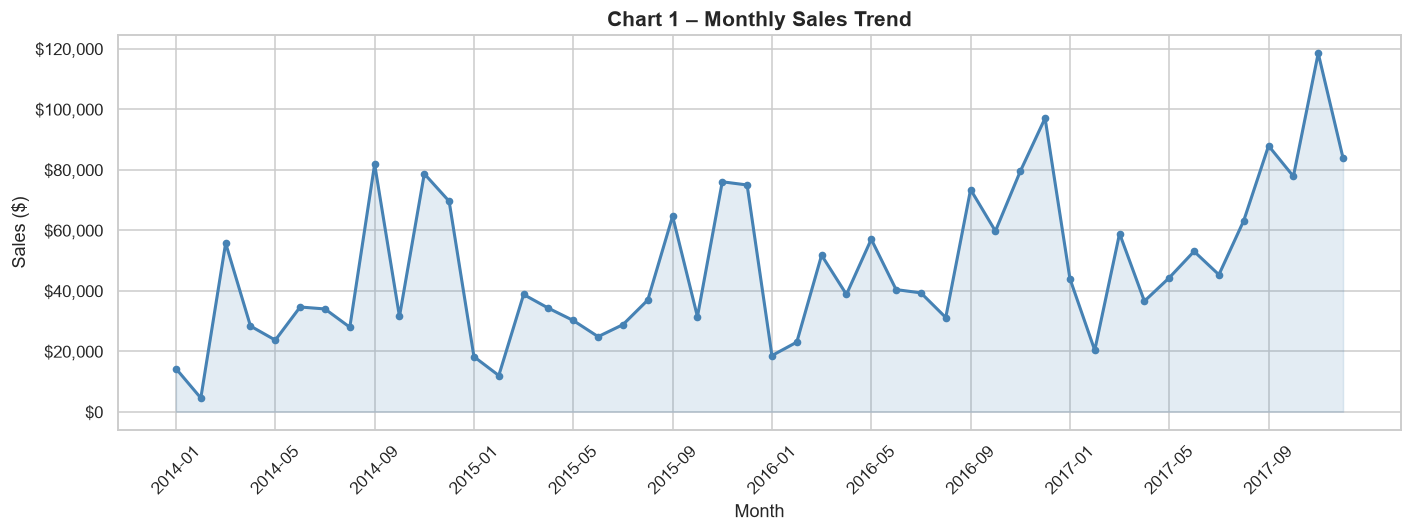

Chart 1 saved.


In [24]:
# ── Chart 1: Monthly Sales Trend ─────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 5))

ax.plot(
    monthly_sales['Month_Label'],
    monthly_sales['Monthly_Sales'],
    marker='o', linewidth=2, color='steelblue', markersize=4
)
ax.fill_between(
    monthly_sales['Month_Label'],
    monthly_sales['Monthly_Sales'],
    alpha=0.15, color='steelblue'
)

# Show only every 4th tick to avoid overcrowding
tick_positions = range(0, len(monthly_sales), 4)
ax.set_xticks([monthly_sales['Month_Label'].iloc[i] for i in tick_positions])
ax.tick_params(axis='x', rotation=45)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Chart 1 – Monthly Sales Trend', fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Sales ($)')
plt.tight_layout()
plt.savefig('chart1_monthly_sales_trend.png', dpi=110)
plt.show()
print('Chart 1 saved.')

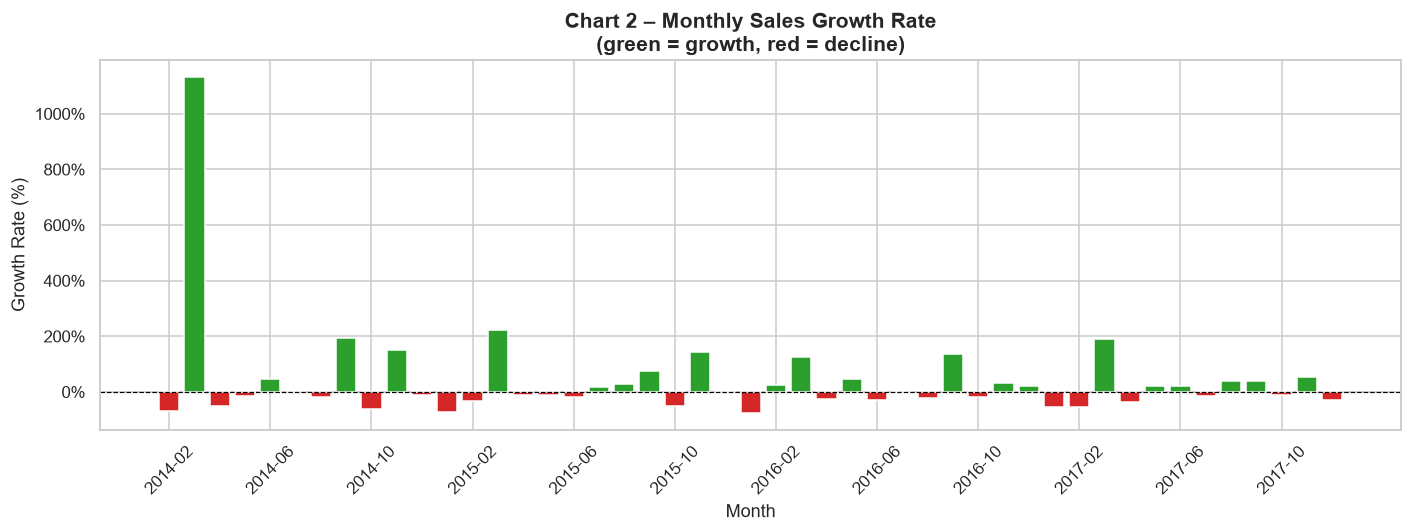

Chart 2 saved.


In [25]:
# ── Chart 2: Monthly Sales Growth Rate ───────────────────────────────────────
growth_data = monthly_sales.dropna(subset=['Growth_Rate_%']).copy()

colors = ['#d62728' if v < 0 else '#2ca02c' for v in growth_data['Growth_Rate_%']]

fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(growth_data['Month_Label'], growth_data['Growth_Rate_%'], color=colors, width=0.8)
ax.axhline(0, color='black', linewidth=0.8, linestyle='--')

tick_positions = range(0, len(growth_data), 4)
ax.set_xticks([growth_data['Month_Label'].iloc[i] for i in tick_positions])
ax.tick_params(axis='x', rotation=45)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{x:.0f}%'))
ax.set_title('Chart 2 – Monthly Sales Growth Rate\n(green = growth, red = decline)',
             fontsize=14, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Growth Rate (%)')
plt.tight_layout()
plt.savefig('chart2_monthly_growth_rate.png', dpi=110)
plt.show()
print('Chart 2 saved.')

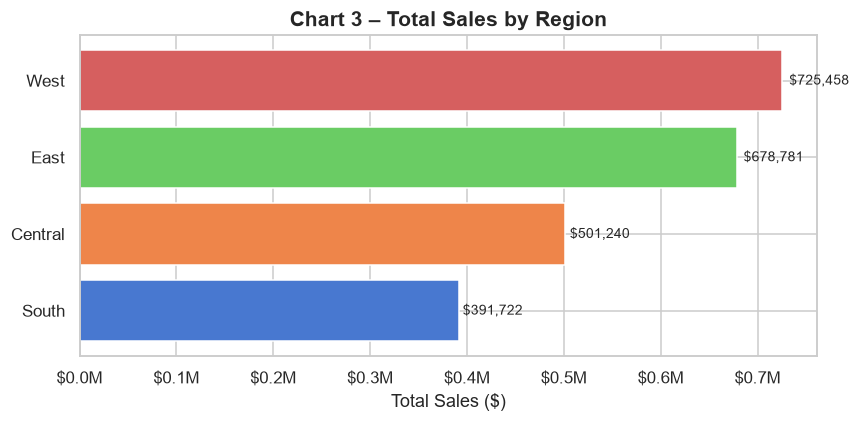

Chart 3 saved.


In [26]:
# ── Chart 3: Sales by Region ──────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(8, 4))

region_plot = region_summary['Sales'].sort_values()
bars = ax.barh(region_plot.index, region_plot.values, color=sns.color_palette('muted', len(region_plot)))

for bar in bars:
    ax.text(
        bar.get_width() + bar.get_width() * 0.01,
        bar.get_y() + bar.get_height() / 2,
        f'${bar.get_width():,.0f}',
        va='center', fontsize=9
    )

ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e6:.1f}M'))
ax.set_title('Chart 3 – Total Sales by Region', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Sales ($)')
plt.tight_layout()
plt.savefig('chart3_sales_by_region.png', dpi=110)
plt.show()
print('Chart 3 saved.')

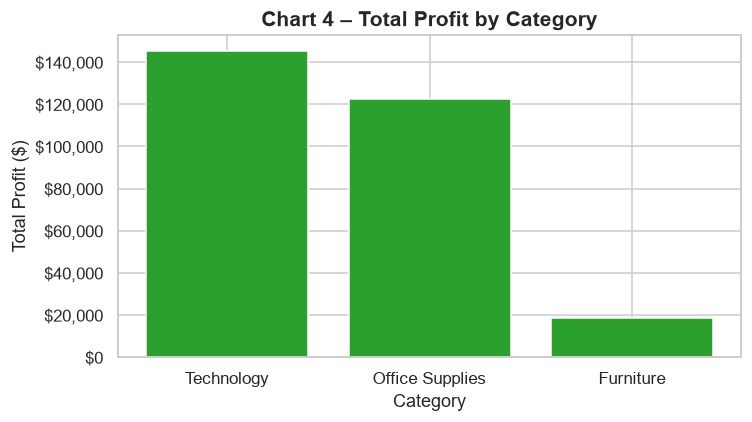

Chart 4 saved.


In [27]:
# ── Chart 4: Profit by Category ───────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 4))

palette = ['#2ca02c' if v > 0 else '#d62728' for v in category_summary['Profit']]
ax.bar(category_summary.index, category_summary['Profit'], color=palette)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Chart 4 – Total Profit by Category', fontsize=14, fontweight='bold')
ax.set_xlabel('Category')
ax.set_ylabel('Total Profit ($)')
ax.axhline(0, color='black', linewidth=0.8)
plt.tight_layout()
plt.savefig('chart4_profit_by_category.png', dpi=110)
plt.show()
print('Chart 4 saved.')

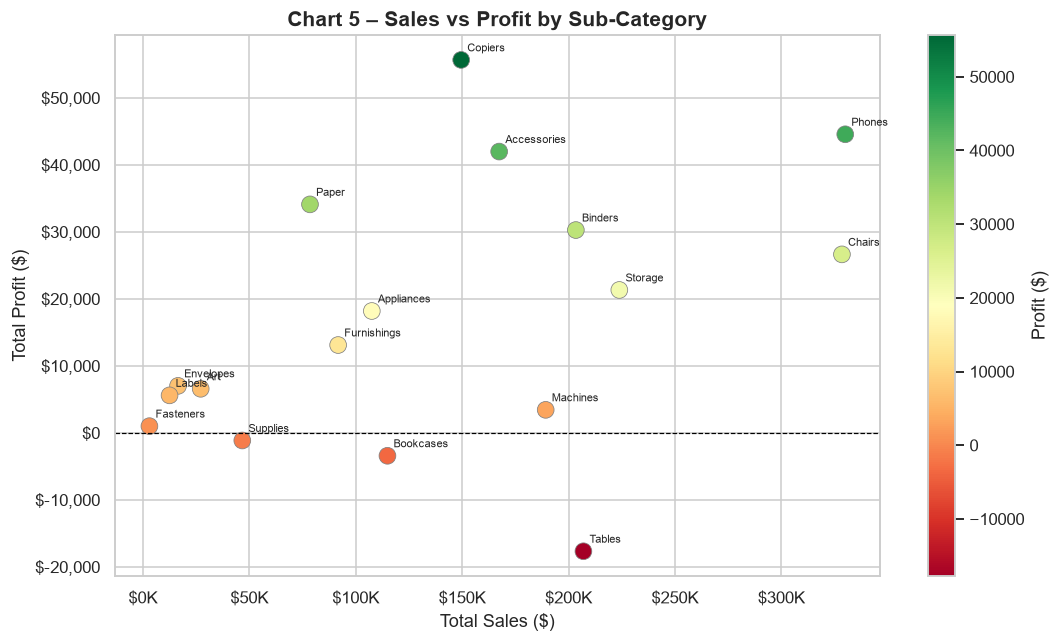

Chart 5 saved.


In [28]:
# ── Chart 5: Sales vs Profit by Sub-Category (scatter) ───────────────────────
fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    sub_summary['Sales'],
    sub_summary['Profit'],
    c=sub_summary['Profit'],
    cmap='RdYlGn',
    s=120, edgecolors='grey', linewidths=0.5
)
plt.colorbar(scatter, ax=ax, label='Profit ($)')

for idx, row in sub_summary.iterrows():
    ax.annotate(
        idx,
        (row['Sales'], row['Profit']),
        fontsize=7.5, ha='left', va='bottom',
        xytext=(4, 4), textcoords='offset points'
    )

ax.axhline(0, color='black', linewidth=0.8, linestyle='--')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x/1e3:.0f}K'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Chart 5 – Sales vs Profit by Sub-Category', fontsize=14, fontweight='bold')
ax.set_xlabel('Total Sales ($)')
ax.set_ylabel('Total Profit ($)')
plt.tight_layout()
plt.savefig('chart5_sales_vs_profit_subcategory.png', dpi=110)
plt.show()
print('Chart 5 saved.')

---
## Section 4 – Machine Learning: Linear Regression

### What we are building
A **simple Linear Regression** model that learns the relationship between
the *month number* (1, 2, 3 …) and *monthly total sales*.  
Given a new month number, the model returns a sales forecast.

### Key concepts explained
| Concept | Plain-English meaning |
|---------|----------------------|
| Feature (X) | The input we give the model — here, the chronological month index |
| Target (y) | What we want to predict — total sales for that month |
| Training set | Past data the model learns patterns from |
| Test set | Held-out future data used to measure how well the model learned |
| MAE | Average absolute prediction error in dollars |
| RMSE | Root-mean-squared error — penalises large errors more than MAE |
| R² | Proportion of variance explained (1.0 = perfect, 0 = no better than the mean) |

### Why we do NOT shuffle time-series data
Shuffling would let the model "see the future" during training, making evaluation results
dishonestly optimistic. We always split chronologically: earlier months → train, later months → test.

In [29]:
# ── 4.1  Prepare monthly aggregation ─────────────────────────────────────────
# We already have monthly_sales from Section 2.
# Add a chronological integer index (1 = first month in dataset, 2 = second, …)

monthly_ml = monthly_sales[['Month_Label', 'Monthly_Sales']].copy().reset_index(drop=True)
monthly_ml['Month_Index'] = np.arange(1, len(monthly_ml) + 1)  # 1-based index

print(f'Total monthly data points: {len(monthly_ml)}')
monthly_ml.head(6)

Total monthly data points: 48


,Month_Label,Monthly_Sales,Month_Index
0,2014-01,14236.8950,1
1,2014-02,4519.8920,2
2,2014-03,55691.0090,3
3,2014-04,28295.3450,4
4,2014-05,23648.2870,5
5,2014-06,34595.1276,6


In [30]:
# ── 4.2  Chronological Train / Test Split ─────────────────────────────────────
# We use the LAST 12 months as the test set and everything before as the training set.
# This simulates predicting one year into the future using historical data.

TEST_SIZE = 12  # last 12 months held out for evaluation

train = monthly_ml.iloc[:-TEST_SIZE].copy()
test  = monthly_ml.iloc[-TEST_SIZE:].copy()

X_train = train[['Month_Index']]
y_train = train['Monthly_Sales']

X_test  = test[['Month_Index']]
y_test  = test['Monthly_Sales']

print(f'Training months : {len(train)}  ({train["Month_Label"].iloc[0]}  →  {train["Month_Label"].iloc[-1]})')
print(f'Test months     : {len(test)}  ({test["Month_Label"].iloc[0]}  →  {test["Month_Label"].iloc[-1]})')

Training months : 36  (2014-01  →  2016-12)
Test months     : 12  (2017-01  →  2017-12)


In [31]:
# ── 4.3  Train the Linear Regression Model ───────────────────────────────────
model = LinearRegression()
model.fit(X_train, y_train)

slope     = model.coef_[0]
intercept = model.intercept_

print('Model trained successfully.')
print(f'  Equation : Monthly Sales = {slope:.2f} × Month_Index + {intercept:.2f}')
print(f'  Interpretation: Sales change by ${slope:+.2f} per month on average.')

Model trained successfully.
  Equation : Monthly Sales = 930.63 × Month_Index + 26227.41
  Interpretation: Sales change by $+930.63 per month on average.


In [32]:
# ── 4.4  Predict on Test Set ─────────────────────────────────────────────────
y_pred = model.predict(X_test)

# ── 4.5  Evaluate the Model ──────────────────────────────────────────────────
mae  = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2   = r2_score(y_test, y_pred)

print('============================================')
print('  MODEL EVALUATION METRICS (Test Set)')
print('============================================')
print(f'  MAE   (Mean Absolute Error) : ${mae:>10,.2f}')
print(f'  RMSE  (Root Mean Sq. Error) : ${rmse:>10,.2f}')
print(f'  R²    (Coefficient of Det.) : {r2:>11.4f}')
print('============================================')
print()
print('Interpretation:')
print(f'  • On average, predictions are off by ${mae:,.0f}.')
print(f'  • R² of {r2:.4f} means the model explains {r2*100:.1f}% of the variance in monthly sales.')
if r2 < 0.5:
    print('  • R² is below 0.5 — the linear trend alone does not capture all sales variation.')
    print('    This is expected: seasonality and promotions are not included as features.')
elif r2 < 0.75:
    print('  • Moderate fit. The overall trend is captured, but month-to-month swings are not.')
else:
    print('  • Good fit. The model captures most of the overall sales trend.')

  MODEL EVALUATION METRICS (Test Set)
  MAE   (Mean Absolute Error) : $ 19,663.55
  RMSE  (Root Mean Sq. Error) : $ 23,664.50
  R²    (Coefficient of Det.) :      0.1570

Interpretation:
  • On average, predictions are off by $19,664.
  • R² of 0.1570 means the model explains 15.7% of the variance in monthly sales.
  • R² is below 0.5 — the linear trend alone does not capture all sales variation.
    This is expected: seasonality and promotions are not included as features.


In [33]:
# ── 4.6  Predict the next 3 months (forecast) ────────────────────────────────
last_index   = monthly_ml['Month_Index'].max()
forecast_idx = np.arange(last_index + 1, last_index + 4).reshape(-1, 1)
forecast_val = model.predict(forecast_idx)

print('3-Month Sales Forecast:')
for i, (idx, val) in enumerate(zip(forecast_idx.flatten(), forecast_val), 1):
    print(f'  Month {idx} (next +{i}) : ${val:>10,.2f}')

print()
print('⚠️  Forecast caveat: these are linear extrapolations only.')
print('   They do not account for seasonality, promotions, or external shocks.')

3-Month Sales Forecast:
  Month 49 (next +1) : $ 71,828.23
  Month 50 (next +2) : $ 72,758.86
  Month 51 (next +3) : $ 73,689.49

⚠️  Forecast caveat: these are linear extrapolations only.
   They do not account for seasonality, promotions, or external shocks.


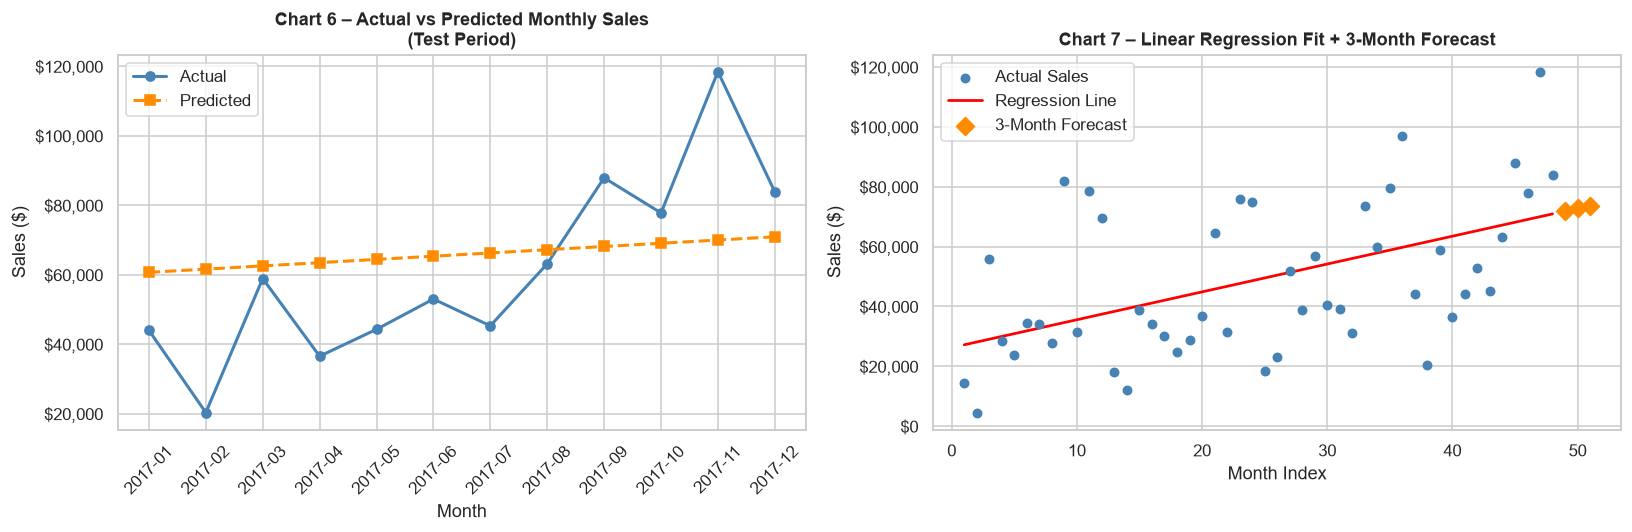

Charts 6 & 7 saved.


In [34]:
# ── Chart 6 & 7: Actual vs Predicted + Regression Line ───────────────────────
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# ---- Chart 6: Actual vs Predicted on test period ----
ax = axes[0]
ax.plot(test['Month_Label'], y_test.values,  label='Actual',    marker='o', color='steelblue', linewidth=2)
ax.plot(test['Month_Label'], y_pred,          label='Predicted', marker='s', color='darkorange', linewidth=2, linestyle='--')
ax.tick_params(axis='x', rotation=45)
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Chart 6 – Actual vs Predicted Monthly Sales\n(Test Period)', fontsize=12, fontweight='bold')
ax.set_xlabel('Month')
ax.set_ylabel('Sales ($)')
ax.legend()

# ---- Chart 7: Full data + regression line + forecast ----
ax = axes[1]
ax.scatter(monthly_ml['Month_Index'], monthly_ml['Monthly_Sales'],
           color='steelblue', s=30, label='Actual Sales', zorder=3)

# Fitted line over the full historical range
x_line = np.arange(1, last_index + 1).reshape(-1, 1)
y_line = model.predict(x_line)
ax.plot(x_line, y_line, color='red', linewidth=1.8, label='Regression Line')

# Forecast points
ax.scatter(forecast_idx, forecast_val, color='darkorange', s=70,
           marker='D', label='3-Month Forecast', zorder=4)

ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'${x:,.0f}'))
ax.set_title('Chart 7 – Linear Regression Fit + 3-Month Forecast', fontsize=12, fontweight='bold')
ax.set_xlabel('Month Index')
ax.set_ylabel('Sales ($)')
ax.legend()

plt.tight_layout()
plt.savefig('chart6_7_actual_vs_predicted.png', dpi=110)
plt.show()
print('Charts 6 & 7 saved.')

### Model Limitations — Important to Understand

Linear Regression with a single time index is the **simplest possible forecasting model**.
It is useful as a starting point, but it has significant limitations:

| Limitation | Why it matters |
|------------|---------------|
| **Assumes linear growth** | Real sales often grow non-linearly or plateau |
| **Ignores seasonality** | Monthly spikes (Black Friday, holidays) appear as noise |
| **No external variables** | Promotions, economic changes, and competitor actions are unmodelled |
| **Extrapolation risk** | Forecasts beyond the training window become increasingly unreliable |
| **Single feature** | Using only month index discards all product, region, and customer information |

> **Next steps for a stronger model:** Add month-of-year as a categorical feature (to capture seasonality),
> use a polynomial regression or a tree-based model, or apply dedicated time-series methods such as SARIMA or Facebook Prophet.

---
## Section 5 – Business Insights

> All findings below are derived from computed values in this notebook.  
> No numbers have been invented or assumed.

Run all cells above first, then read the output of the cells below.

In [35]:
# ── 5.1  Key Findings ─────────────────────────────────────────────────────────
top_region    = region_summary['Sales'].idxmax()
top_region_s  = region_summary.loc[top_region, 'Sales']
top_category  = category_summary['Profit'].idxmax()
loss_sub      = sub_summary['Profit'].idxmin()
loss_sub_p    = sub_summary.loc[loss_sub, 'Profit']
best_growth   = monthly_sales['Growth_Rate_%'].max()
worst_growth  = monthly_sales['Growth_Rate_%'].min()

print('════════════════════════════════════════════════════')
print('  5 KEY FINDINGS')
print('════════════════════════════════════════════════════')
print(f'1. Total sales of ${total_sales:,.0f} generated a profit of ${total_profit:,.0f}')
print(f'   (overall profit margin: {profit_margin:.2f}%).')
print()
print(f'2. The "{top_region}" region leads all regions in total sales')
print(f'   at ${top_region_s:,.0f}.')
print()
print(f'3. "{top_category}" is the most profitable product category.')
print()
print(f'4. "{loss_sub}" sub-category has the lowest (or most negative) profit')
print(f'   at ${loss_sub_p:,.0f}, signalling a potential pricing or cost issue.')
print()
print(f'5. Month-over-month sales growth ranged from {worst_growth:.1f}% to {best_growth:.1f}%,')
print(f'   with an average of {avg_growth:.1f}%, indicating considerable volatility.')
print('════════════════════════════════════════════════════')

════════════════════════════════════════════════════
  5 KEY FINDINGS
════════════════════════════════════════════════════
1. Total sales of $2,297,201 generated a profit of $286,397
   (overall profit margin: 12.47%).

2. The "West" region leads all regions in total sales
   at $725,458.

3. "Technology" is the most profitable product category.

4. "Tables" sub-category has the lowest (or most negative) profit
   at $-17,725, signalling a potential pricing or cost issue.

5. Month-over-month sales growth ranged from -75.2% to 1132.1%,
   with an average of 41.6%, indicating considerable volatility.
════════════════════════════════════════════════════


In [36]:
# ── 5.2  Risks ────────────────────────────────────────────────────────────────
print('════════════════════════════════════════════════════')
print('  3 IDENTIFIED RISKS')
print('════════════════════════════════════════════════════')
print(f'R1. Loss-making sub-category: "{loss_sub}" is eroding overall profit.')
print(f'    Action needed: review supplier costs or adjust retail prices.')
print()
print(f'R2. Sales volatility ({worst_growth:.1f}% to {best_growth:.1f}%) makes revenue forecasting difficult.')
print(f'    This limits inventory planning and cash-flow management.')
print()
print( 'R3. Linear Regression R² may be low, showing the model alone cannot reliably')
print( '    forecast sales. Over-reliance on this model for business decisions is risky.')
print('════════════════════════════════════════════════════')

════════════════════════════════════════════════════
  3 IDENTIFIED RISKS
════════════════════════════════════════════════════
R1. Loss-making sub-category: "Tables" is eroding overall profit.
    Action needed: review supplier costs or adjust retail prices.

R2. Sales volatility (-75.2% to 1132.1%) makes revenue forecasting difficult.
    This limits inventory planning and cash-flow management.

R3. Linear Regression R² may be low, showing the model alone cannot reliably
    forecast sales. Over-reliance on this model for business decisions is risky.
════════════════════════════════════════════════════


In [37]:
# ── 5.3  Opportunities ────────────────────────────────────────────────────────
bottom_region = region_summary['Sales'].idxmin()

print('════════════════════════════════════════════════════')
print('  3 IDENTIFIED OPPORTUNITIES')
print('════════════════════════════════════════════════════')
print(f'O1. The "{bottom_region}" region shows the lowest sales — targeted marketing')
print(f'    campaigns could grow its revenue closer to the {top_region} region level.')
print()
print(f'O2. The "{top_category}" category has strong margins.')
print(f'    Increasing its share of total inventory could lift overall profitability.')
print()
print( 'O3. High-sales months identified in the growth-rate chart suggest seasonal')
print( '    peaks. Stocking up ahead of those peaks can capture additional revenue.')
print('════════════════════════════════════════════════════')

════════════════════════════════════════════════════
  3 IDENTIFIED OPPORTUNITIES
════════════════════════════════════════════════════
O1. The "South" region shows the lowest sales — targeted marketing
    campaigns could grow its revenue closer to the West region level.

O2. The "Technology" category has strong margins.
    Increasing its share of total inventory could lift overall profitability.

O3. High-sales months identified in the growth-rate chart suggest seasonal
    peaks. Stocking up ahead of those peaks can capture additional revenue.
════════════════════════════════════════════════════


In [38]:
# ── 5.4  Recommended Actions ─────────────────────────────────────────────────
print('════════════════════════════════════════════════════')
print('  5 RECOMMENDED ACTIONS')
print('════════════════════════════════════════════════════')
print(f'A1. Investigate and address the losses in "{loss_sub}" sub-category')
print( '    (pricing review, supplier negotiation, or product discontinuation).')
print()
print(f'A2. Increase marketing spend in the "{bottom_region}" region')
print( '    to drive incremental sales growth.')
print()
print( 'A3. Build seasonal stock plans using the monthly sales trend chart to')
print( '    avoid stockouts during high-demand months.')
print()
print( 'A4. Improve the forecasting model by adding month-of-year dummy variables')
print( '    to capture seasonality — this should meaningfully raise R².')
print()
print( 'A5. Set up a monthly KPI dashboard tracking: Total Sales, Profit Margin,')
print( '    Growth Rate, and Regional Performance to enable rapid decision-making.')
print('════════════════════════════════════════════════════')

════════════════════════════════════════════════════
  5 RECOMMENDED ACTIONS
════════════════════════════════════════════════════
A1. Investigate and address the losses in "Tables" sub-category
    (pricing review, supplier negotiation, or product discontinuation).

A2. Increase marketing spend in the "South" region
    to drive incremental sales growth.

A3. Build seasonal stock plans using the monthly sales trend chart to
    avoid stockouts during high-demand months.

A4. Improve the forecasting model by adding month-of-year dummy variables
    to capture seasonality — this should meaningfully raise R².

A5. Set up a monthly KPI dashboard tracking: Total Sales, Profit Margin,
    Growth Rate, and Regional Performance to enable rapid decision-making.
════════════════════════════════════════════════════


---
## Section 6 – Conclusion

This project demonstrated a full analytics pipeline on real retail data:

1. **Data Cleaning** — we handled encoding issues, parsed dates, removed duplicates,
   stripped whitespace, and validated numeric columns before any analysis began.

2. **EDA** — we computed business KPIs (total sales, profit margin, regional breakdown)
   and identified high-performing categories and loss-making sub-categories.

3. **Visualisations** — seven charts made the data patterns immediately visible,
   from overall sales trends to sub-category profitability scatter plots.

4. **Machine Learning** — a Linear Regression model was trained on chronological
   monthly data, evaluated honestly with MAE / RMSE / R², and used to produce
   a 3-month sales forecast with clearly stated limitations.

5. **Business Insights** — five key findings, three risks, three opportunities,
   and five recommended actions were derived entirely from computed values.

### What you learned
- How to clean real-world tabular data with Pandas
- How to compute and present business KPIs
- How to visualise time-series and categorical data
- How to train and evaluate a Linear Regression model correctly
- Why honest evaluation (avoiding data leakage, stating limitations) matters

---
*Project completed by Itika Kansal — Data Analytics & ML Internship*